## 

In [1]:
%run 0_requirements.ipynb

In [2]:
# file = Path(r"/data/credit_risk_dataset.csv")
# df = pd.read_csv(file)
# df.head()

In [3]:
# Dataset importing using KaggleHub (https://www.kaggle.com/datasets/laotse/credit-risk-dataset/data)
file_path = "credit_risk_dataset.csv"

df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "laotse/credit-risk-dataset",
  file_path
)

C:\Users\Marcus\AppData\Local\Temp\ipykernel_12244\4076531318.py:4: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


### Importação dos dados de trabalho  
Considerando o dataset de trabalho, foi realizada a importação dos dados e posteriormente visualização das características da base (quantidade de ids, atributos, tipos de dados, outliers e valores nulos). Obtido em https://www.kaggle.com/datasets/laotse/credit-risk-dataset/data

In [4]:
print(df.head())
print(df.shape)
print(df.isnull().sum())
print(df.info())
print(df.describe())

   person_age  person_income person_home_ownership  person_emp_length  \
0          22          59000                  RENT              123.0   
1          21           9600                   OWN                5.0   
2          25           9600              MORTGAGE                1.0   
3          23          65500                  RENT                4.0   
4          24          54400                  RENT                8.0   

  loan_intent loan_grade  loan_amnt  loan_int_rate  loan_status  \
0    PERSONAL          D      35000          16.02            1   
1   EDUCATION          B       1000          11.14            0   
2     MEDICAL          C       5500          12.87            1   
3     MEDICAL          C      35000          15.23            1   
4     MEDICAL          C      35000          14.27            1   

   loan_percent_income cb_person_default_on_file  cb_person_cred_hist_length  
0                 0.59                         Y                           3  


Existem 12 atributos e 32.581 linhas, das quais 895 são nulas em _person_emp_length_ e 3.116 são nulas em _loan_int_rate_.  
Existem ouliers nos atributos _person_age_ e _person_emp_length_.

In [5]:
TARGET = "loan_status" #Target variable

#Prep data for modeling
X = df.drop(columns=[TARGET]) # explanatory variables
y = df[TARGET] # target variable

# Class distribution verifying
print(f"Quantity of default values: {y.value_counts()}")

print(f" Proportion of default values: {y.value_counts(normalize=True) * 100}")

Quantity of default values: loan_status
0    25473
1     7108
Name: count, dtype: int64
 Proportion of default values: loan_status
0    78.183604
1    21.816396
Name: proportion, dtype: float64


Definida a variável-alvo _loan_status_, foi realizada a separação das variáveis preditoras _X_ e variável alvo _y_. Temos cerca de 22% dos dados em _default_ (alvo de predição)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Test:", X_test.shape)

Training: (26064, 11)
Test: (6517, 11)


Separação dos dados de treino e teste em uma proporção de 80% para treino e 20% para teste, buscando manter a proporção de variáveis-alvo em ambos datasets a partir do `stratify`.

In [7]:
def cap_outliers(X):
    X = X.copy()
    
    X["person_age"] = X["person_age"].clip(
        upper=100
    )

    X["person_emp_length"] = X["person_emp_length"].clip(
        upper=50
    )

    return X

Função criada para tratamento dos outliers identificados inicialmente em _person_age_ e _person_emp_length_



In [8]:
# Set up numeric features
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Set up category features
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print(f"Num variables: {numeric_features}")
print(f"Cat variables: {categorical_features}")

Num variables: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
Cat variables: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


Visando o pré-processamento das variáveis preditoras, foi criada 2 variáveis contendo todas as colunas enquadradas em variáveis numéricas e categóricas.

In [9]:
# Numeric variables treatment
numeric_transformer = Pipeline(steps=[
    ("outliers", FunctionTransformer(
        cap_outliers,
        validate=False
    )),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# Categorical variables treatment
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])


# Combining treatments
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

A preparação dos dados numéricos e categóricos foi realizada com a função `Pipeline` do `sklearn`.   

Para os dados numéricos removi os outliers com a função `cap_ouliers` (definida anteriormente), a função `SimpleImputer` garante que os dados nulos sejam tratados (nesse caso utilizando a mediana) e, por fim, foi feita a padronização dos dados com `StandardScaler` (evitando grandes distorções em valores numéricos que possam afetar a predição do modelo).  

Para os dados categóricos, em relação aos valores nulos foi utilizada a visão de maior frequência de aparição e, posteriormente, feito o `OneHotEncoder` transformando os dados categóricos em números para consumo pelo processo de treinamentos dos modelos.

In [10]:
# Models definition and hiperparameters
models = {
    "Logistic Regression": {
        "model": LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ),
        "params": {
            "model__C": [0.01, 0.1, 1, 10, 100],
            "model__solver": ["lbfgs"]
        }
    },
    "Decision Tree": {
        "model": DecisionTreeClassifier(
            class_weight="balanced",
            random_state=42
        ),
        "params": {
            "model__max_depth": [3, 5, 8, 10, 15, None],
            "model__min_samples_split": [2, 5, 10, 20],
            "model__min_samples_leaf": [1, 5, 10, 20],
            "model__criterion": ["gini", "entropy"]
        }
    },
    "Random Forest": {
        "model": RandomForestClassifier(
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),
        "params": {
            "model__n_estimators": [100, 200, 300],
            "model__max_depth": [5, 10, 15, None],
            "model__min_samples_split": [2, 5, 10],
            "model__min_samples_leaf": [1, 2, 5],
            "model__max_features": ["sqrt", "log2"]
        }
    },
    "Extra Trees": {
        "model": ExtraTreesClassifier(
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),
        "params": {
            "model__n_estimators": [100, 200, 300],
            "model__max_depth": [5, 10, 15, None],
            "model__min_samples_split": [2, 5, 10],
            "model__min_samples_leaf": [1, 2, 5],
            "model__max_features": ["sqrt", "log2"]
        }
    },
    "Gradient Boosting": {
        "model": GradientBoostingClassifier(
            random_state=42
        ),
        "params": {
            "model__n_estimators": [100, 150, 200],
            "model__learning_rate": [0.01, 0.05, 0.1],
            "model__max_depth": [2, 3, 4],
            "model__min_samples_split": [2, 5, 10],
            "model__min_samples_leaf": [1, 3, 5],
            "model__subsample": [0.8, 1.0]
        }
    },
    "XGBoost": {
        "model": XGBClassifier(
            objective="binary:logistic",
            eval_metric="aucpr",
            random_state=42,
            n_jobs=1
        ),
        "params": {
            "model__n_estimators": [100, 300, 500],
            "model__learning_rate": [0.01, 0.04, 0.1],
            "model__max_depth": [3, 5, 6],
            "model__subsample": [0.7, 0.85, 1.0],
            "model__min_child_weight": [1, 4, 7],
            "model__colsample_bytree": [0.7, 0.85, 1.0],
            "model__gamma": [0, 0.2, 0.5],
            "model__reg_alpha": [0, 0.5, 1],
            "model__reg_lambda": [1, 4, 10]
        }
    }
}

Definição dos modelos e hiperparâmetros

  * `LogisticRegression (sklearn)`: busca de relação ponderada entre as variáveis e o alvo (_default_)ç
  * `DecisionTreeClassifier (sklearn)`: encontra possíveis motivadores para o alvo a partir dos valores de cada variável em forma de uma árvore de decisão;
  * `RandomForestClassifier (sklearn)`: cria uma floresta de árvores de decisão e o resultado final representa a probabilidade agregada de todas as árvores;
  * `ExtraTreesClassifier (sklearn)`: similar a `RandomForestClassifier`, porém, seleciona os atributos aleatoriamente, o que traz maior diversidade sobre a análise;
  * `GradientBoostingClassifier (sklearn)`: cria árvores de decisão (similar a `RandomForestClassifier`), mas no que tange ao treinamento, esse é feito individualmente e corrigindo possíveis erros do conjunto de árvores anterior;
  * `XGBClassifier (xgboost)`: similar ao `GradientBoostingClassifier`, agregando mecanismos de regularização (redução da complexidade do modelo) e eficiência computacional (como pode ser evidenciado no tempo de treinamento a seguir).

In [11]:
# os.makedirs("models", exist_ok=True)
# os.makedirs("results", exist_ok=True)

# Cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# Result storage
results = []
trained_models = {}

# Training loop
for name, config in models.items():
    print("\n" + "=" * 60)
    print(f"Training model: {name}")
    print("=" * 60)

    # Timer start
    total_start = time.perf_counter()

    # Pipeline creation
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", config["model"])
    ])

    # Hiperparam search
    
    # search = GridSearchCV(
    #     estimator=pipeline,
    #     param_grid=config["params"],
    #     cv=cv,
    #     scoring="average_precision",
    #     n_jobs=-1
    # )

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=config["params"],
        n_iter=10,
        scoring="average_precision",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        verbose=1
    )

    # Training timer start
    training_start = time.perf_counter()

    # Training
    search.fit(X_train, y_train)

    # Training time
    training_time = time.perf_counter() - training_start

    # Best model
    best_model = search.best_estimator_

    # Predictions
    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]

    # Metrics
    metrics = {
        "Model": name,
        "CV_PR_AUC": search.best_score_,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, y_prob),
        "PR_AUC": average_precision_score(y_test, y_prob),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_test, y_pred
        ),
        "Training_Time_Seconds": round(training_time, 2)
    }

    results.append(metrics)

    # Saving model
    trained_models[name] = best_model
    filename = name.lower().replace(" ", "_")

    joblib.dump(
        best_model,
        f"models/{filename}.joblib"
    )

    # Time overall
    total_time = time.perf_counter() - total_start

    print("\nBest hiperparamters:")
    print(search.best_params_)
    print("\nMetrics:")
    print(metrics)
    print("\nClassification report:")
    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )

    print(f"\nTraining time: {training_time:.2f} seconds")
    print(f"Total execution time: {total_time:.2f} seconds")


Training model: Logistic Regression
Fitting 5 folds for each of 5 candidates, totalling 25 fits


c:\Users\Marcus\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 5 is smaller than n_iter=10. Running 5 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(



Best hiperparamters:
{'model__solver': 'lbfgs', 'model__C': 10}

Metrics:
{'Model': 'Logistic Regression', 'CV_PR_AUC': np.float64(0.7158030810609362), 'Accuracy': 0.8140248580635262, 'Precision': 0.5523952095808383, 'Recall': 0.7784810126582279, 'F1': 0.6462346760070052, 'ROC_AUC': np.float64(0.8712057407154362), 'PR_AUC': np.float64(0.7210189135864402), 'Balanced_Accuracy': np.float64(0.801213028409585), 'Training_Time_Seconds': 4.78}

Classification report:
              precision    recall  f1-score   support

           0       0.93      0.82      0.87      5095
           1       0.55      0.78      0.65      1422

    accuracy                           0.81      6517
   macro avg       0.74      0.80      0.76      6517
weighted avg       0.85      0.81      0.82      6517


Training time: 4.78 seconds
Total execution time: 4.82 seconds

Training model: Decision Tree
Fitting 5 folds for each of 10 candidates, totalling 50 fits

Best hiperparamters:
{'model__min_samples_split': 

A estratégia de otimização de hiperparâmetros (`RandomizedSearchCV`) utilizou _cross-validation_ com 5 splits, ou seja, os dados de treino e teste serao divididos em 5 subsets possibilitando maior aprendizado aos modelos .  
O objetivo é testar 6 modelos sobre o dataset. Logo, foi criado um loop sobre o dicionário de modelos (`models`).  
O loop consiste em:
* Identificação de qual modelo está em execução e inicio do timer geral
* Definição do `Pipeline` 
 * Pré-processamento (definido anteriormente)
 * Utilização dos hiperparâmetros de cada modelo
* Definição do _cross-validation_ buscando a experimentação de combinações de hiperparâmetros aleatoriamente:
 * Objetivo de 10 iterações em 5 folds (cerca de 50 testes de combinações), utilizando todos os núcleos de processamento disponíveis
* Armazenamento em variável da melhor modelo testado (combinação de hiperparâmetros) em `best_model` para posterior comparação entre modelos
* Cálculo das métricas para comparação dos melhores modelos
 * O melhor modelo foi definido a partir da `average_precision_score` das cross-validations (_CV_PR_AUC_)
* Armazenamento o melhor modelo treinado


In [12]:
# Results dataframe
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="CV_PR_AUC",
    ascending=False
)
print(results_df.to_string(index=False))

# Results save
results_df.to_csv(
    "results/models_comparison.csv",
    index=False
)

              Model  CV_PR_AUC  Accuracy  Precision   Recall       F1  ROC_AUC   PR_AUC  Balanced_Accuracy  Training_Time_Seconds
            XGBoost   0.899997  0.934479   0.965388 0.725738 0.828583 0.951593 0.907118           0.859238                   4.65
  Gradient Boosting   0.897978  0.934172   0.965323 0.724332 0.827642 0.946673 0.903674           0.858535                  22.59
      Random Forest   0.883259  0.929415   0.940476 0.722222 0.817025 0.930457 0.880534           0.854732                  11.69
      Decision Tree   0.854857  0.873408   0.682569 0.784810 0.730128 0.911360 0.853256           0.841473                   1.07
        Extra Trees   0.837018  0.891361   0.758696 0.736287 0.747323 0.908434 0.837873           0.835464                   8.59
Logistic Regression   0.715803  0.814025   0.552395 0.778481 0.646235 0.871206 0.721019           0.801213                   4.78


Os resultados estatísticos dos dados foram armazenados para comparação entre os modelos. O melhor modelo foi classificado pela métrica `CV_PR_AUC`, sendo o XGBoost visto que foi o melhor na identificação média da variável-alvo (_default_)

Uma breve explicação sobre cada indicador para facilitar o entendimento do usuário (para todos, interpretar quanto maior melhor):
* `Accuracy`: avalia os acertos gerais (_default_ e _nao_default_) em relação aos dados-alvos totais;
* `Precision`: avalia entre todos os casos classificados como _default_, quantos, de fato, acertaram;
* `Recall`: avalia entre todos os casos _default_, quantos foram classificados corretamente;
* `F1`: combina a relacao de `Precision` e `Recall` entre as classes _default_;
* `ROC_AUC`: avalia o quão bem o modelo classifica _default_ e _nao_default_;
* `PR_AUC`: avalia o quão bem o modelo classifica _default_ e _nao_default_ levando em consideração a classificação dos casso _default_;
* `CV_PR_AUC`: ;
* `Balanced_Accuracy`: combina a relacao de recall entre as classes _default_ e _nao_default_.

O `Training_Time_Seconds` também foi exibido para avaliar o custo-benefício do treinamento e implementação


In [13]:
# Selecting best perfomance model on cross-validation
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

print("Best model:", best_name)

# Best model save
joblib.dump(
    best_model,
    f"models/best_credit_risk_model_{best_name}.joblib"
)

Best model: XGBoost


['models/best_credit_risk_model_XGBoost.joblib']

Devidamente identificado o melhor modelo, o código salva o melhor modelo para uso posterior.

In [14]:
metadata = {
    "model_name": best_name,
    "target": TARGET,
    "threshold": 0.50,
    "selection_metric": "CV_PR_AUC",
    "random_state": 42
}

with open(
    f"models/model_metadata_{best_name}.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        metadata,
        file,
        indent=4,
        ensure_ascii=False
    )

O mesmo é feito com os hiperparâmetros utilizados no melhor modelo.

Data prediction quantity: 6517


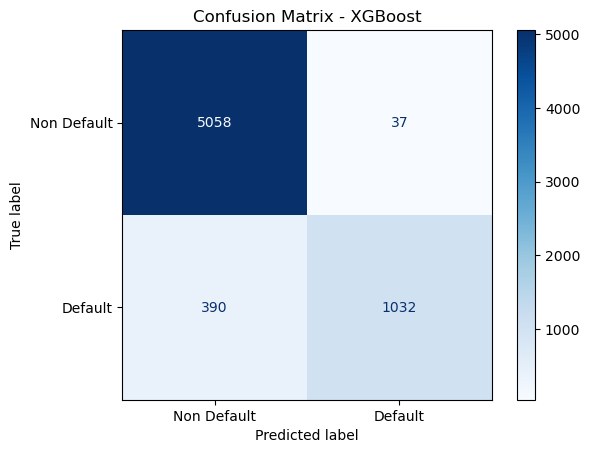

In [15]:
# Best model predictions
y_pred_best = best_model.predict(X_test)
print(f"Data prediction quantity: {y_pred_best.shape[0]}")

# Confusion matrix setup and plot
cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=[0, 1]
)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non Default", "Default"]
)

disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix - {best_name}")

plt.show()



É possível evidenciar que o modelo obteve uma excelente performance de `Recall` nos casos _nao_default_. Já nos casos _default_ obteve um `Recall` de 72,6% (uma nova versão buscará melhorar essa performance, talvez sacrificando parte da `Precision`)

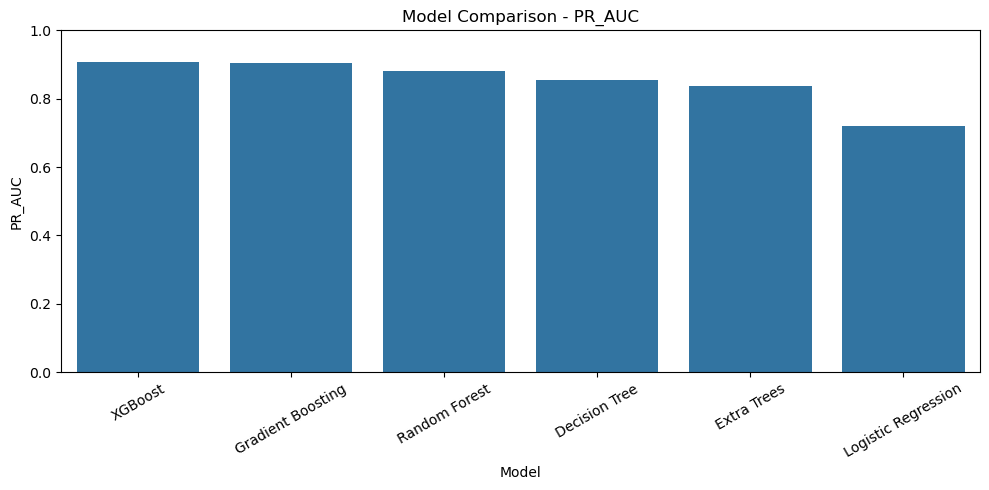

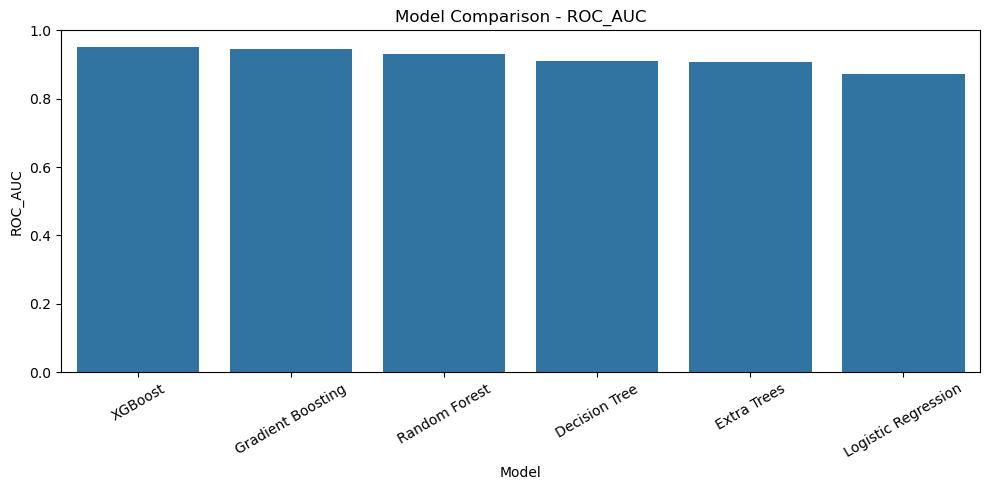

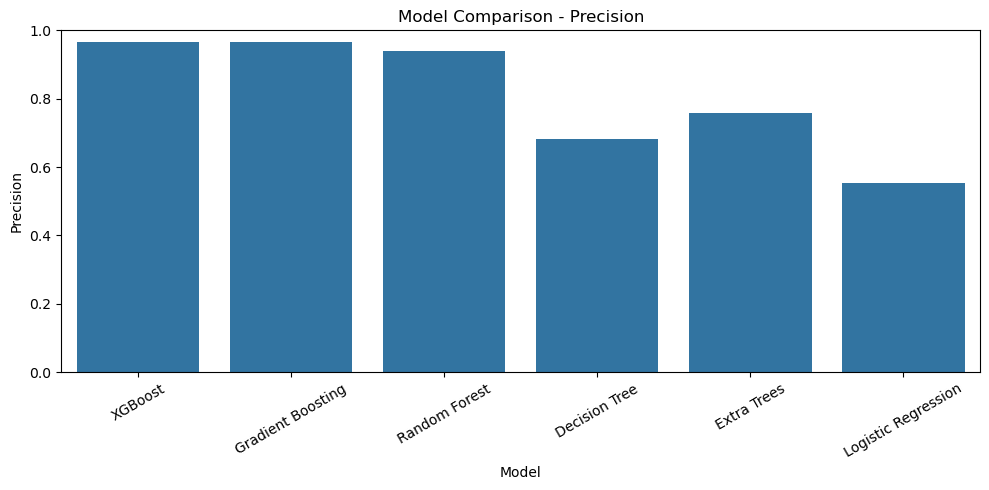

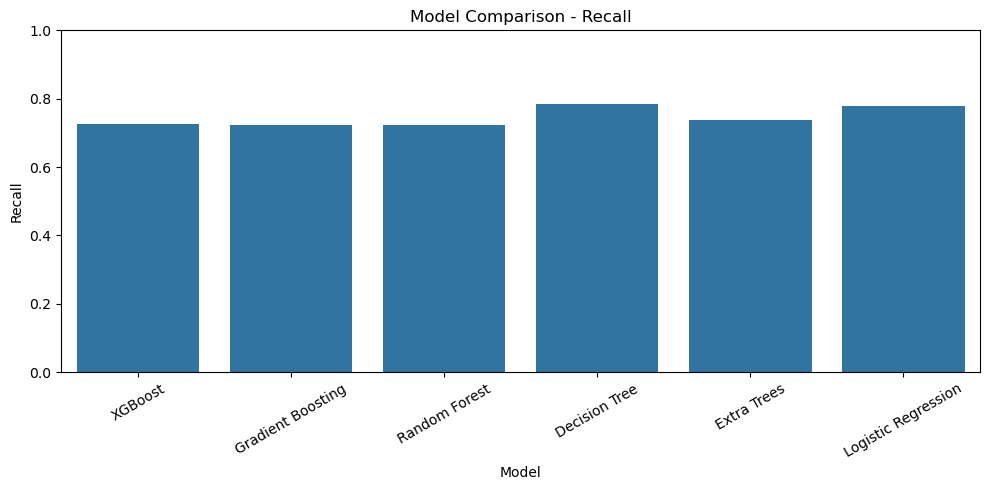

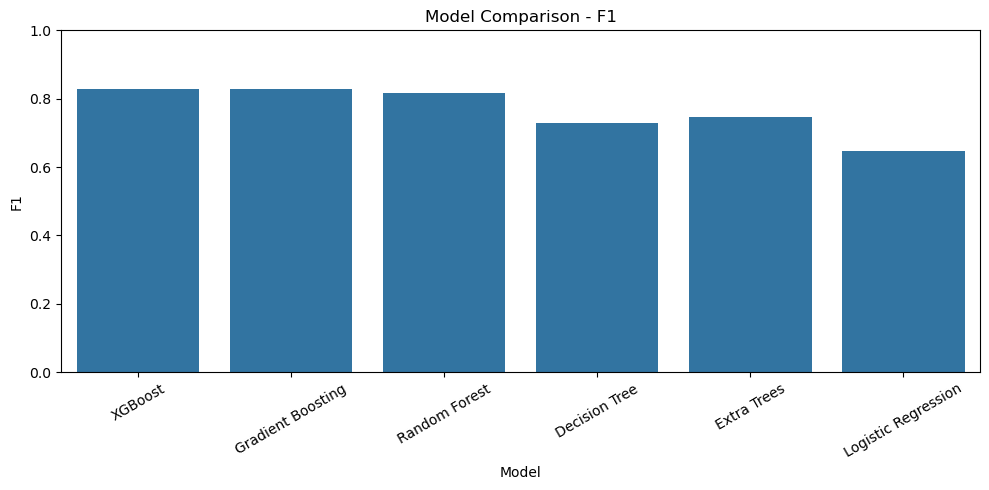

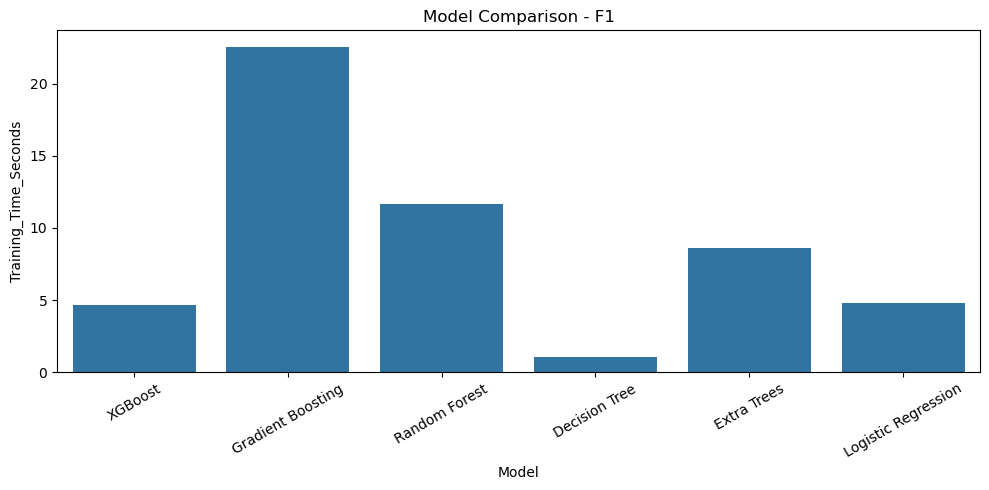

In [16]:
# Identificação das variáveis mais importantes

metrics_to_plot = [
    "PR_AUC",
    "ROC_AUC",
    "Precision",
    "Recall",
    "F1"  
]

for metric in metrics_to_plot:
    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xticks(rotation=30)
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

# #Training time
plt.figure(figsize=(10, 5))
sns.barplot(
    data=results_df,
    x="Model",
    y="Training_Time_Seconds"
)

plt.title(f"Model Comparison - {metric}")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

                      Variable  Importance  Standard_Deviation
8          loan_percent_income    0.281410            0.007542
2        person_home_ownership    0.193453            0.008868
1                person_income    0.166124            0.005123
4                  loan_intent    0.087908            0.004444
5                   loan_grade    0.083808            0.002721
7                loan_int_rate    0.040741            0.001451
3            person_emp_length    0.016359            0.000889
0                   person_age    0.009206            0.000451
6                    loan_amnt    0.007246            0.000534
10  cb_person_cred_hist_length   -0.000029            0.000194
9    cb_person_default_on_file   -0.000702            0.000134


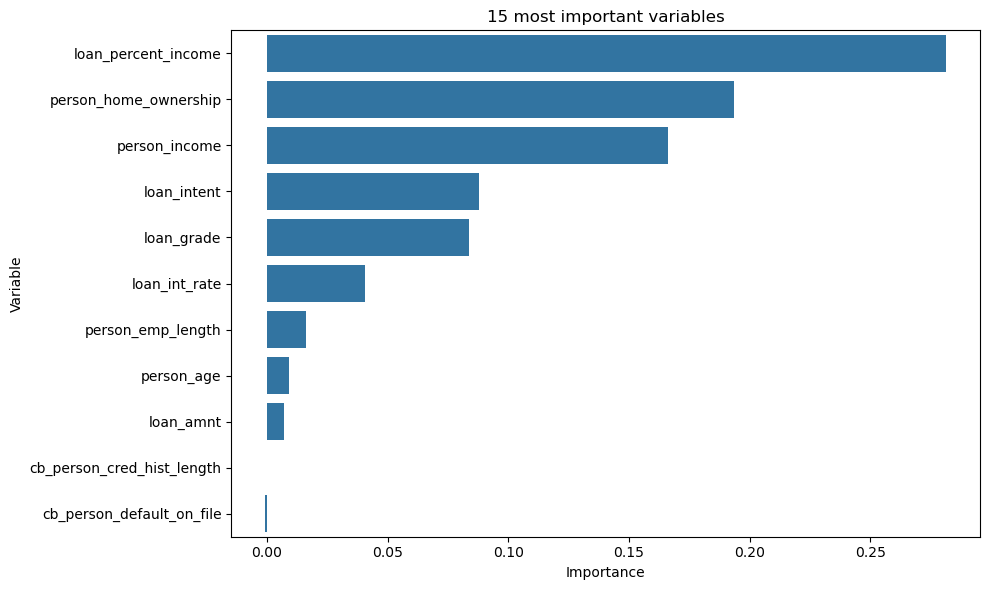

In [17]:
# Finds the most important variables for the model
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Variable": X_test.columns,
    "Importance": importance.importances_mean,
    "Standard_Deviation": importance.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

# Gráfico
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Variable"
)
plt.title("15 most important variables")
plt.tight_layout()
plt.show()

# Salvando
importance_df.to_csv(
    "results/variable_importance.csv",
    index=False

)

As variáveis que mais impactaram o modelo foram 
* loan_percent_income: 28,14%
* person_home_ownership: 19,35%
* person_income: 16,61%
* 64% no total